# ERCOT Day-Ahead Load Forecasting with an LSTM
**ASDS 6304 Final Project · Group 3 · LSTM component**

This notebook builds the deep-learning forecaster described in the proposal (Section 4.1–4.2):

| Proposal requirement | Where it is handled here |
|---|---|
| At the end of day *d*, forecast `system_total_mw` for all 24 hours of day *d+1* | §4 sample construction (direct 24-output model) |
| Inputs: past demand sequence + calendar features; **no future observed weather** | §4 (weather used only in the labelled upper-bound experiment, §9) |
| One system record per hour; careful DST handling | §2 data audit, §3 regular hourly grid |
| Chronological split: train 2018–2023, validate 2024–2025, test 2026 | §4, using the `split` column from the cleaned file |
| Scalers fitted on training data only | §4 |
| LSTM trained with **mini-batch SGD** | §6 (SGD with Nesterov momentum, gradient clipping, LR schedule, early stopping) |
| Hyperparameters: one fixed set, kept in a single `CONFIG` cell | §0 `CONFIG`; tuning hooks for a teammate in §12 (validation only) |
| Test year evaluated once | §7 |
| MAE / RMSE in MW, seasonal-naive benchmark, by season, peak days, lead hour, paired day-level comparison | §5, §7, §8 |
| Optimizer behaviour: objective decrease, gradient norm, runtime, inference time, model size | §7, §10 |
| Winter Storm Uri robustness check | §9 |
| Forecasts handed to the battery-dispatch QP | §11 exports `lstm_outputs/lstm_day_ahead_forecasts.csv` |

Select a Python 3 kernel with NumPy, pandas, Matplotlib, SciPy, and PyTorch installed, then run all cells. The notebook uses the included `ercot_system_hourly_cleaned.csv` and writes results to `lstm_outputs/` beside it. CPU runtime depends on the machine and the number of training epochs.

**For the hyperparameter-tuning teammate:** every tunable setting lives in the `CONFIG` dictionary in §0, and §12 gives a `run_trial()` function that trains any setting and scores it on the **2024–2025 validation years only**. The test year is never used for tuning. Once you pick a setting, paste it into `CONFIG` and re-run the whole notebook.

## 0. Setup

In [1]:
import time, json, copy, math, os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import torch
except ModuleNotFoundError as exc:
    if exc.name != "torch":
        raise
    raise ModuleNotFoundError(
        "Install PyTorch in the selected notebook kernel. For a Windows CPU kernel, "
        "run %pip install torch --index-url https://download.pytorch.org/whl/cpu "
        "--extra-index-url https://pypi.org/simple "
        "in a notebook cell, then restart the kernel."
    ) from exc
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from pandas.tseries.holiday import USFederalHolidayCalendar
from scipy import stats

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

data_filename = "ercot_system_hourly_cleaned.csv"
data_candidates = (
    Path.cwd() / data_filename,
    Path.cwd() / "data" / data_filename,
    Path.cwd() / "final project" / "data" / data_filename,
)
DATA_PATH = next((path for path in data_candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        f"Could not find {data_filename}. Start the kernel from the notebook's folder, "
        "the final project folder, or the workspace root."
    )
OUT_DIR = DATA_PATH.parent / "lstm_outputs"
OUT_DIR.mkdir(exist_ok=True)

HORIZON = 24                 # forecast all 24 hours of day d+1 (fixed by the proposal, not tunable)
SEED = 42                    # seed for single runs and tuning trials
FINAL_SEEDS = [42, 7, 2026]  # final model = average of these three training runs

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu" and "OMP_NUM_THREADS" not in os.environ:
    # Small LSTM batches can spend more time coordinating threads than computing.
    torch.set_num_threads(min(4, torch.get_num_threads()))
print("PyTorch", torch.__version__, "| device:", device)

# =====================================================================
# HYPERPARAMETERS: the single place to change model / training settings
# ---------------------------------------------------------------------
# This is the one fixed setting used for every result in this notebook.
# Tuning (teammate): try alternatives with run_trial() in Section 12,
# then copy the chosen values here and re-run the notebook top to bottom.
# =====================================================================
CONFIG = {
    # --- input design (Section 4) ---
    "mode":        "day",   # "day": one LSTM step per past day (24 loads + calendar)
                            # "hour": one LSTM step per past hour (slower, ~6x)
    "lookback":    14,      # days of history fed to the LSTM
    "level_days":  7,       # days averaged to normalise each sample (removes load growth)
    # --- network (Section 6) ---
    "hidden":      64,      # LSTM hidden units
    "layers":      2,       # stacked LSTM layers
    "dropout":     0.2,     # dropout between LSTM layers and in the output head
    "head_units":  128,     # width of the dense layer after the LSTM
    # --- mini-batch SGD (Section 6) ---
    "optimizer":   "sgd_nesterov",  # "sgd", "sgd_nesterov" or "adam"
    "lr":          0.03,    # initial step size
    "momentum":    0.9,     # ignored for "sgd" (plain) and "adam"
    "batch":       32,      # target days per mini-batch
    "wd":          0.0,     # L2 weight decay
    "clip":        1.0,     # gradient-norm clipping threshold
    # --- step-size schedule and stopping ---
    "lr_factor":   0.5,     # multiply lr by this when validation loss stalls ...
    "lr_patience": 8,       # ... for this many epochs
    "max_epochs":  200,
    "patience":    25,      # early stopping: epochs without validation improvement
}
print(json.dumps(CONFIG, indent=1))

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

PyTorch 2.15.0+cpu | device: cpu
{
 "mode": "day",
 "lookback": 14,
 "level_days": 7,
 "hidden": 64,
 "layers": 2,
 "dropout": 0.2,
 "head_units": 128,
 "optimizer": "sgd_nesterov",
 "lr": 0.03,
 "momentum": 0.9,
 "batch": 32,
 "wd": 0.0,
 "clip": 1.0,
 "lr_factor": 0.5,
 "lr_patience": 8,
 "max_epochs": 200,
 "patience": 25
}


## 1. Load the cleaned system table
The cleaned file already has one **system** row per timestamp (the zone rows from the original 619,968-row table were collapsed by a teammate), plus weather means, zone loads, the `uri_flag` and the chronological `split` label.

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
print(raw.shape)
raw.head()

(77496, 21)


,timestamp,DSTFlag,source,uri_flag,split,system_total_mw,zone_load_sum_mw,temp_mean,dwpt_mean,rhum_mean,...,prcp_mean,temp_f_mean,load_coast_mw,load_east_mw,load_farWest_mw,load_north_mw,load_northC_mw,load_southC_mw,load_southern_mw,load_west_mw
0,2018-01-01 00:00:00,False,archive,False,train,"50,567.070","50,567.070",-3.825,-9.037,68.125,...,0.000,25.125,"11,425.979","1,852.664","2,823.409","1,135.361","18,584.344","9,151.191","3,831.649","1,762.473"
1,2018-01-01 01:00:00,False,archive,False,train,"50,617.088","50,617.088",-4.225,-9.162,69.250,...,0.000,24.400,"11,408.418","1,850.169","2,809.745","1,136.631","18,524.141","9,144.994","3,988.271","1,754.718"
2,2018-01-01 02:00:00,False,archive,False,train,"50,694.300","50,694.300",-4.575,-9.562,68.750,...,0.000,23.762,"11,405.198","1,858.270","2,797.803","1,135.930","18,532.057","9,141.037","4,076.086","1,747.920"
3,2018-01-01 03:00:00,False,archive,False,train,"50,999.592","50,999.592",-4.862,-10.150,66.875,...,0.000,23.250,"11,450.560","1,879.624","2,807.794","1,146.069","18,647.445","9,157.957","4,154.940","1,755.203"
4,2018-01-01 04:00:00,False,archive,False,train,"51,723.732","51,723.732",-5.350,-10.537,67.250,...,0.000,22.375,"11,631.337","1,876.481","2,822.989","1,154.187","19,002.102","9,214.334","4,247.452","1,774.850"


## 2. Data audit (proposal §3.2)

In [3]:
ts = raw["timestamp"]
gaps = ts.diff()
zone_cols = [c for c in raw.columns if c.startswith("load_")]

audit = {
    "rows": len(raw),
    "columns": raw.shape[1],
    "first timestamp": ts.min(),
    "last timestamp": ts.max(),
    "missing values (any column)": int(raw.isna().sum().sum()),
    "duplicate timestamps (fall-back DST hour)": int(ts.duplicated().sum()),
    "rows with DSTFlag=True": int(raw["DSTFlag"].sum()),
    "1-hour gaps skipped (spring-forward DST)": int((gaps == pd.Timedelta("2h")).sum()),
    "longer gaps": [str(t) for t in ts[gaps > pd.Timedelta("2h")]],
    "API rows (vs archive)": int((raw["source"] == "api").sum()),
    "Uri-flagged hours": int(raw["uri_flag"].sum()),
    "max |system - sum(zones)| (MW)": float((raw["system_total_mw"] - raw[zone_cols].sum(axis=1)).abs().max()),
}
for k, v in audit.items():
    print(f"{k:45s} {v}")

print("\nSplit ranges in the cleaned file:")
print(raw.groupby("split")["timestamp"].agg(["min", "max", "count"]))
print("\nUri window:", raw.loc[raw.uri_flag, "timestamp"].min(), "->", raw.loc[raw.uri_flag, "timestamp"].max())

rows                                          77496
columns                                       21
first timestamp                               2018-01-01 00:00:00
last timestamp                                2026-11-04 23:00:00
missing values (any column)                   0
duplicate timestamps (fall-back DST hour)     9
rows with DSTFlag=True                        9
1-hour gaps skipped (spring-forward DST)      9
longer gaps                                   ['2026-10-31 00:00:00']
API rows (vs archive)                         817
Uri-flagged hours                             168
max |system - sum(zones)| (MW)                2359.831268999995

Split ranges in the cleaned file:
             min                 max  count
split                                      
test  2026-01-01 2026-11-04 23:00:00   7368
train 2018-01-01 2023-12-31 23:00:00  52584
val   2024-01-01 2025-12-31 23:00:00  17544

Uri window: 2021-02-14 00:00:00 -> 2021-02-20 23:00:00


**What the audit shows and how it is handled**

* Timestamps are local clock time. Each November the repeated 01:00 hour appears twice (`DSTFlag=True` marks the second copy), and each March the 02:00 hour does not exist.
* To give every day exactly 24 hourly slots (needed for a 24-output forecast), §3 **averages the two fall-back 01:00 readings** and **linearly interpolates the single missing spring-forward 02:00 hour**.
* One whole day is absent near the end of the test period. It is never used as a forecast target; where it falls inside an *input* window it is filled with the same hour one week earlier.
* The few hours where the system total differs from the zone sum are small relative to ~50 GW and are left as is.

## 3. Regular local-time hourly grid

In [4]:
NUM_COLS = ["system_total_mw", "temp_f_mean", "dwpt_mean", "rhum_mean", "wspd_mean", "prcp_mean"]

# 1) collapse the duplicated fall-back hour
g = raw.groupby("timestamp").agg({**{c: "mean" for c in NUM_COLS}, "uri_flag": "max"})

# 2) reindex to a complete 24-slot-per-day grid
full_idx = pd.date_range(g.index.min().normalize(),
                         g.index.max().normalize() + pd.Timedelta(hours=23), freq="h")
hourly = g.reindex(full_idx)
hourly["was_missing"] = hourly["system_total_mw"].isna()

# 3) interpolate isolated single missing hours (spring-forward)
na = hourly["system_total_mw"].isna()
run_len = na.groupby((na != na.shift()).cumsum()).transform("sum")
single = na & (run_len == 1)
for c in NUM_COLS:
    hourly.loc[single, c] = hourly[c].interpolate(limit_area="inside")[single]

# 4) whole missing days: fill inputs with the same hour one week earlier (never scored)
for c in NUM_COLS:
    hourly[c] = hourly[c].fillna(hourly[c].shift(168))
hourly["uri_flag"] = hourly["uri_flag"].fillna(False).astype(bool)

assert hourly[NUM_COLS].isna().sum().sum() == 0
assert len(hourly) % 24 == 0
print("Interpolated single hours:", int(single.sum()))
print("Hours filled from previous week:", int((hourly["was_missing"] & ~single).sum()))
print("Grid:", hourly.index.min(), "->", hourly.index.max(), f"({len(hourly)//24} days)")

Interpolated single hours: 9
Hours filled from previous week: 24
Grid: 2018-01-01 00:00:00 -> 2026-11-04 23:00:00 (3230 days)


In [5]:
# Day x hour matrices
days = pd.DatetimeIndex(hourly.index[::24])
n_days = len(days)
L = hourly["system_total_mw"].to_numpy().reshape(n_days, 24)              # load (MW)
TEMP = hourly["temp_f_mean"].to_numpy().reshape(n_days, 24)              # only for upper-bound run
DWPT = hourly["dwpt_mean"].to_numpy().reshape(n_days, 24)
imputed_hours = hourly["was_missing"].to_numpy().reshape(n_days, 24).sum(1)
day_uri = hourly["uri_flag"].to_numpy().reshape(n_days, 24).any(1)
day_target_ok = imputed_hours <= 1     # spring-forward days (1 interpolated hour) are fine; whole missing day is not

# Day-level split (by calendar year, matches the `split` column)
day_split = np.where(days.year <= 2023, "train", np.where(days.year <= 2025, "val", "test"))
chk = raw.assign(date=raw.timestamp.dt.normalize()).groupby("date")["split"].first()
assert (chk.reindex(days).dropna() == pd.Series(day_split, index=days)[chk.reindex(days).notna()]).all()

# Calendar features
hol = USFederalHolidayCalendar().holidays(days.min(), days.max())
dow = days.day_of_week.to_numpy()
doy = days.day_of_year.to_numpy()
is_hol = days.isin(hol)
offday = ((dow >= 5) | is_hol).astype(float)

print(pd.Series(day_split).value_counts(), "\nUri days:", int(day_uri.sum()),
      "| unusable target days:", list(days[~day_target_ok].date))

train    2191
val       731
test      308
Name: count, dtype: int64 
Uri days: 7 | unusable target days: [datetime.date(2026, 10, 30)]


### Quick look: why a sequence model?
Load at the same hour is strongly correlated with 1 day and 7 days earlier, so a window of the last 1–4 weeks of hourly demand carries most of the day-ahead signal. The LSTM's job is to learn how to weight that recent history together with the calendar.

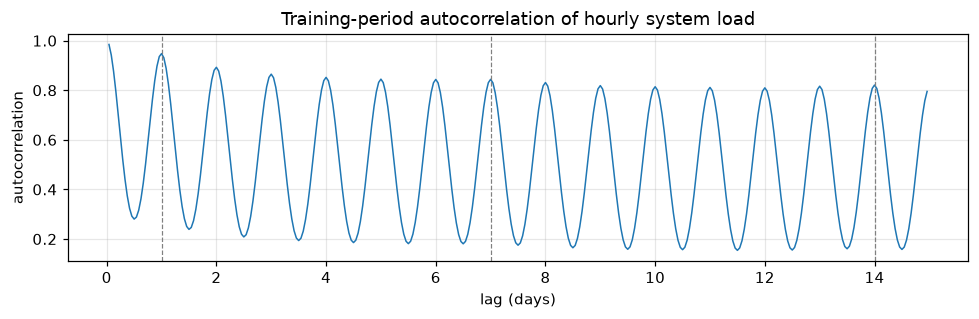

In [6]:
y_tr = hourly.loc[hourly.index.year <= 2023, "system_total_mw"]
lags = np.arange(1, 24 * 15)
acf = [y_tr.autocorr(l) for l in lags]
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(lags / 24, acf, lw=1)
for d in (1, 7, 14):
    ax.axvline(d, color="grey", ls="--", lw=0.8)
ax.set(xlabel="lag (days)", ylabel="autocorrelation", title="Training-period autocorrelation of hourly system load")
plt.tight_layout(); plt.show()

## 4. Leakage-safe forecasting samples
For each target day *d+1*, the forecast is issued at the end of day *d* and may only use data up to 23:00 on day *d*.

**Normalising by a recent level.** ERCOT demand grew ~25% over 2018–2026 (proposal Fig. 1), so the 2026 test loads are higher than anything in training. Instead of scaling raw MW, every sample is divided by its own **level** = mean load over the `level_days` (default 7) days before issuance. The network predicts the *shape relative to recent demand*; multiplying back by the level restores MW. This uses only past data and removes most of the trend.

**Inputs**
* **Sequence** (`CONFIG["mode"]`; the default is day-step):
  * *day-step*: one LSTM step per past day; each step holds that day's 24 relative loads + day-of-week (sin/cos) + off-day flag + day-of-year (sin/cos).
  * *hour-step*: one LSTM step per past hour (168 steps); each step holds relative load + hour, day-of-week (sin/cos) + off-day flag.
* **Static target-day features** (known in advance): day-of-week one-hot, off-day flag (weekend or federal holiday), day-of-year sin/cos, and log-level (standardised on training).

**Target:** the 24 relative loads of day *d+1*, standardised with training statistics.

In [7]:
def cyc(v, period):
    return np.sin(2 * np.pi * v / period), np.cos(2 * np.pi * v / period)

dow_s, dow_c = cyc(dow, 7)
doy_s, doy_c = cyc(doy, 365.25)
DAY_CAL = np.column_stack([dow_s, dow_c, offday, doy_s, doy_c])          # 5 per-day calendar features
HOUR_S, HOUR_C = cyc(np.arange(24), 24)

def build_samples(lookback_days, mode="day", level_days=7, use_weather=False):
    # Return dict of numpy arrays for every usable target day.
    start = max(lookback_days, level_days)
    rows = []
    for t in range(start, n_days):
        if not day_target_ok[t]:
            continue
        rows.append(t)
    rows = np.array(rows)

    level = np.array([L[t - level_days:t].mean() for t in rows])                      # MW
    seq_load = np.stack([L[t - lookback_days:t] for t in rows]) / level[:, None, None]  # (n, LB, 24)
    y_rel = L[rows] / level[:, None]                                                   # (n, 24)

    if mode == "day":
        cal = np.stack([DAY_CAL[t - lookback_days:t] for t in rows])                   # (n, LB, 5)
        seq = (seq_load, cal)
    else:  # hour-step: flatten to (n, LB*24, 1) + hourly calendar
        n = len(rows)
        load_h = seq_load.reshape(n, -1, 1)
        hour_feats = np.tile(np.column_stack([HOUR_S, HOUR_C]), (lookback_days, 1))     # (LB*24, 2)
        day_feats = np.stack([np.repeat(DAY_CAL[t - lookback_days:t, :3], 24, axis=0) for t in rows])
        cal = np.concatenate([np.broadcast_to(hour_feats, (n,) + hour_feats.shape), day_feats], axis=2)
        seq = (load_h, cal)

    dow_onehot = np.eye(7)[dow[rows]]
    static = np.column_stack([dow_onehot, offday[rows], doy_s[rows], doy_c[rows], np.log(level)])
    if use_weather:   # UPPER BOUND ONLY: observed target-day weather would not be known at issuance
        static = np.column_stack([static, TEMP[rows], DWPT[rows]])

    return dict(rows=rows, level=level, seq_load=seq[0], seq_cal=seq[1], static=static, y_rel=y_rel,
                split=day_split[rows], uri=np.array([day_uri[t - lookback_days:t + 1].any() for t in rows]))


class Scaler:
    # Fit standardisation on TRAINING samples only, apply to all splits.
    def fit(self, S, train_mask):
        tr = train_mask
        self.mu_load = S["seq_load"][tr].mean(); self.sd_load = S["seq_load"][tr].std()
        self.mu_y, self.sd_y = self.mu_load, self.sd_load          # same scale for inputs and target
        self.mu_st = S["static"][tr].mean(0); self.sd_st = S["static"][tr].std(0)
        self.sd_st[self.sd_st == 0] = 1.0
        onehot = slice(0, 8)                                         # leave one-hots / off-day flag unscaled
        self.mu_st[onehot] = 0.0; self.sd_st[onehot] = 1.0
        return self

    def transform(self, S):
        seq = np.concatenate([((S["seq_load"] - self.mu_load) / self.sd_load), S["seq_cal"]], axis=2)
        static = (S["static"] - self.mu_st) / self.sd_st
        y = (S["y_rel"] - self.mu_y) / self.sd_y
        return seq.astype(np.float32), static.astype(np.float32), y.astype(np.float32)

    def to_mw(self, y_std, level):
        return (y_std * self.sd_y + self.mu_y) * level[:, None]


def make_data(cfg, use_weather=False, exclude_uri_train=True):
    # Build tensors for a config. Only the input-design keys (mode, lookback, level_days) matter here.
    S = build_samples(cfg["lookback"], cfg["mode"], cfg["level_days"], use_weather)
    train_mask = (S["split"] == "train") & ~(S["uri"] if exclude_uri_train else np.zeros_like(S["uri"]))
    sc = Scaler().fit(S, train_mask)
    seq, static, y = sc.transform(S)
    masks = {"train": train_mask, "val": S["split"] == "val", "test": S["split"] == "test"}
    tensors = {k: tuple(torch.tensor(a[m]) for a in (seq, static, y)) for k, m in masks.items()}
    return dict(S=S, scaler=sc, masks=masks, tensors=tensors,
                n_seq=seq.shape[2], n_static=static.shape[1])

DATA = make_data(CONFIG)
D = DATA
for k, m in D["masks"].items():
    print(f"{k:5s}: {m.sum():5d} target days | seq tensor {tuple(D['tensors'][k][0].shape)}")
print("Uri-affected training samples dropped from main fit:", int(((D['S']['split']=='train') & D['S']['uri']).sum()))

train:  2156 target days | seq tensor (2156, 14, 29)
val  :   731 target days | seq tensor (731, 14, 29)
test :   307 target days | seq tensor (307, 14, 29)
Uri-affected training samples dropped from main fit: 21


## 5. Benchmarks and metrics
The seasonal-naive forecasts from the proposal are computed on exactly the same target days, so every comparison is like for like:
* **previous day**: day *d+1* = day *d*
* **previous week**: day *d+1* = day *d−6* (same weekday)

In [8]:
def metrics(actual, pred):
    a, p = np.asarray(actual).ravel(), np.asarray(pred).ravel()
    err = p - a
    return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err ** 2).mean()),
            "MAPE%": 100 * np.abs(err / a).mean(),
            "sMAPE%": 100 * (2 * np.abs(err) / (np.abs(a) + np.abs(p))).mean()}

def naive_forecasts(rows):
    return {"Naive: previous day": L[rows - 1], "Naive: previous week": L[rows - 7]}

S = D["S"]
bench = []
for split in ["val", "test"]:
    rows = S["rows"][D["masks"][split]]
    for name, pred in naive_forecasts(rows).items():
        bench.append({"split": split, "model": name, **metrics(L[rows], pred)})
bench = pd.DataFrame(bench)
bench

,split,model,MAE,RMSE,MAPE%,sMAPE%
0,val,Naive: previous day,"2,425.726","3,497.145",4.513,4.504
1,val,Naive: previous week,"4,614.663","6,478.327",8.520,8.432
2,test,Naive: previous day,"2,405.851","3,377.377",4.166,4.143
3,test,Naive: previous week,"4,564.418","6,295.033",7.920,7.835


## 6. LSTM model and mini-batch SGD training loop

**Architecture.** A 2-layer LSTM reads the input sequence; its final hidden state is concatenated with the static target-day features and passed through a small MLP head that outputs all 24 hours at once (a *direct* multi-output forecast, so there is no error feedback across lead hours).

**Optimisation (the course angle).** The training objective is the mean squared error on standardised targets,
$$f(\theta)=\frac{1}{24N}\sum_{i=1}^{N}\lVert \hat y_i(\theta)-y_i\rVert_2^2 ,$$
which is non-convex in the network weights θ. It is minimised with **mini-batch SGD**:
* batches of 32 target days drawn without replacement each epoch (samples are separate windows, so shuffling them does not break the chronological split);
* **Nesterov momentum** 0.9;
* **gradient-norm clipping** at 1.0, the standard safeguard against exploding gradients in recurrent nets. The *pre-clipping* norm is logged as a diagnostic;
* **step-size schedule**: halve the learning rate when validation loss stalls for 8 epochs;
* **early stopping** on validation loss (patience 25), restoring the best weights.

All of these values come from `CONFIG` in §0.

Each epoch logs the full-batch training objective (eval mode, no dropout), validation loss, validation MAE in MW, mean gradient norm, learning rate and wall time.

In [9]:
class LSTMForecaster(nn.Module):
    def __init__(self, n_seq, n_static, hidden=64, layers=2, dropout=0.2, head_units=128, horizon=HORIZON):
        super().__init__()
        self.lstm = nn.LSTM(n_seq, hidden, num_layers=layers, batch_first=True,
                            dropout=dropout if layers > 1 else 0.0)
        self.head = nn.Sequential(nn.Linear(hidden + n_static, head_units), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(head_units, horizon))

    def forward(self, x_seq, x_static):
        _, (h, _) = self.lstm(x_seq)
        return self.head(torch.cat([h[-1], x_static], dim=1))


def make_optimizer(cfg, params):
    name = cfg["optimizer"]
    if name == "sgd":
        return torch.optim.SGD(params, lr=cfg["lr"], momentum=0.0, weight_decay=cfg["wd"])
    if name == "sgd_nesterov":
        return torch.optim.SGD(params, lr=cfg["lr"], momentum=cfg["momentum"], nesterov=True, weight_decay=cfg["wd"])
    if name == "adam":
        return torch.optim.Adam(params, lr=cfg["lr"], weight_decay=cfg["wd"])
    raise ValueError(name)


@torch.no_grad()
def predict_std(model, seq, static, batch=512):
    model.eval()
    return torch.cat([model(seq[i:i + batch].to(device), static[i:i + batch].to(device)).cpu()
                      for i in range(0, len(seq), batch)]).numpy()


def train_model(cfg, data, seed=SEED, verbose=False):
    cfg = {**CONFIG, **cfg}          # any key not given falls back to CONFIG
    set_seed(seed)
    tr, va = data["tensors"]["train"], data["tensors"]["val"]
    model = LSTMForecaster(data["n_seq"], data["n_static"], cfg["hidden"], cfg["layers"],
                           cfg["dropout"], cfg["head_units"]).to(device)
    opt = make_optimizer(cfg, model.parameters())
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=cfg["lr_factor"], patience=cfg["lr_patience"])
    gen = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(*tr), batch_size=cfg["batch"], shuffle=True, generator=gen)
    loss_fn = nn.MSELoss()
    S, sc = data["S"], data["scaler"]
    va_rows = data["masks"]["val"]

    hist = {k: [] for k in ["epoch", "train_obj", "val_loss", "val_mae_mw", "grad_norm", "lr", "time"]}
    best, best_state, wait, t0 = np.inf, None, 0, time.perf_counter()
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train(); gnorms = []
        for xb, sb, yb in loader:
            xb, sb, yb = xb.to(device), sb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb, sb), yb)
            loss.backward()
            gnorms.append(float(nn.utils.clip_grad_norm_(model.parameters(), cfg["clip"])))
            opt.step()

        p_tr = predict_std(model, tr[0], tr[1]); p_va = predict_std(model, va[0], va[1])
        train_obj = float(((p_tr - tr[2].numpy()) ** 2).mean())
        val_loss = float(((p_va - va[2].numpy()) ** 2).mean())
        val_mae = np.abs(sc.to_mw(p_va, S["level"][va_rows]) - L[S["rows"][va_rows]]).mean()
        sched.step(val_loss)

        for k, v in zip(hist, [epoch, train_obj, val_loss, val_mae, np.mean(gnorms),
                               opt.param_groups[0]["lr"], time.perf_counter() - t0]):
            hist[k].append(v)
        if verbose and (epoch % 20 == 0 or epoch == 1):
            print(f"ep {epoch:3d} train {train_obj:.4f} val {val_loss:.4f} valMAE {val_mae:7.0f} MW "
                  f"|g| {np.mean(gnorms):.3f} lr {opt.param_groups[0]['lr']:.4g}")

        if val_loss < best - 1e-5:
            best, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break

    model.load_state_dict(best_state)
    hist = pd.DataFrame(hist)
    hist.attrs["best_epoch"] = int(hist.loc[hist.val_loss.idxmin(), "epoch"])
    hist.attrs["train_seconds"] = hist["time"].iloc[-1]
    return model, hist


def forecast_mw(model, data, split):
    seq, static, _ = data["tensors"][split]
    m = data["masks"][split]
    return data["scaler"].to_mw(predict_std(model, seq, static), data["S"]["level"][m])

n_params = lambda m: sum(p.numel() for p in m.parameters())

## 7. Train the LSTM with `CONFIG` (3 seeds), then evaluate the test year once
SGD on a non-convex objective lands in different local minima depending on initialisation and batch order. Training the same configuration with three seeds shows how much of the result is the model and how much is luck. The **reported LSTM forecast is the average of the three runs**, and the spread across seeds is reported alongside it.

In [10]:
S, M = DATA["S"], DATA["masks"]
final_models, final_hists, seed_rows = {}, {}, []
for s in FINAL_SEEDS:
    model, hist = train_model(CONFIG, DATA, seed=s, verbose=(s == FINAL_SEEDS[0]))
    final_models[s], final_hists[s] = model, hist
    for split in ["val", "test"]:
        rows = S["rows"][M[split]]
        seed_rows.append({"seed": s, "split": split, **metrics(L[rows], forecast_mw(model, DATA, split)),
                          "best epoch": hist.attrs["best_epoch"], "train s": hist.attrs["train_seconds"]})
seed_tab = pd.DataFrame(seed_rows)
display(seed_tab)
print(seed_tab.groupby("split")[["MAE", "RMSE", "MAPE%"]].agg(["mean", "std"]))

ep   1 train 0.3665 val 0.3134 valMAE    3458 MW |g| 0.232 lr 0.03
ep  20 train 0.1167 val 0.1041 valMAE    1827 MW |g| 0.282 lr 0.03
ep  40 train 0.0989 val 0.0981 valMAE    1766 MW |g| 0.256 lr 0.03
ep  60 train 0.0925 val 0.0930 valMAE    1678 MW |g| 0.249 lr 0.03
ep  80 train 0.0875 val 0.0904 valMAE    1658 MW |g| 0.251 lr 0.0075


,seed,split,MAE,RMSE,MAPE%,sMAPE%,best epoch,train s
0,42,val,"1,645.631","2,493.098",2.964,2.962,58,35.691
1,42,test,"1,735.163","2,542.682",2.877,2.888,58,35.691
2,7,val,"1,622.421","2,479.717",2.924,2.917,102,53.394
3,7,test,"1,702.110","2,501.676",2.825,2.823,102,53.394
4,2026,val,"1,640.386","2,492.096",2.949,2.951,70,38.141
5,2026,test,"1,720.131","2,515.352",2.847,2.857,70,38.141


            MAE             RMSE        MAPE%      
           mean    std      mean    std  mean   std
split                                              
test  1,719.134 16.549 2,519.903 20.878 2.850 0.026
val   1,636.146 12.172 2,488.304  7.453 2.945 0.020


In [11]:
# Ensemble forecast (mean of seeds) + inference timing
pred = {}
for split in ["val", "test"]:
    pred[split] = np.mean([forecast_mw(m, DATA, split) for m in final_models.values()], axis=0)

seq_te, st_te, _ = DATA["tensors"]["test"]
t0 = time.perf_counter()
for _ in range(20):
    predict_std(final_models[FINAL_SEEDS[0]], seq_te, st_te)
infer_ms_per_day = (time.perf_counter() - t0) / 20 / len(seq_te) * 1000

summary = []
for split in ["val", "test"]:
    rows = S["rows"][M[split]]
    summary.append({"split": split, "model": "LSTM (3-seed mean)", **metrics(L[rows], pred[split])})
    for name, p in naive_forecasts(rows).items():
        summary.append({"split": split, "model": name, **metrics(L[rows], p)})
summary = pd.DataFrame(summary)
display(summary)
print(f"Parameters per LSTM: {n_params(final_models[FINAL_SEEDS[0]]):,} | "
      f"inference: {infer_ms_per_day:.3f} ms per 24-hour forecast | "
      f"mean training time per seed: {np.mean([h.attrs['train_seconds'] for h in final_hists.values()]):.0f} s")

,split,model,MAE,RMSE,MAPE%,sMAPE%
0,val,LSTM (3-seed mean),"1,621.872","2,475.196",2.917,2.915
1,val,Naive: previous day,"2,425.726","3,497.145",4.513,4.504
2,val,Naive: previous week,"4,614.663","6,478.327",8.520,8.432
3,test,LSTM (3-seed mean),"1,696.546","2,502.326",2.809,2.815
4,test,Naive: previous day,"2,405.851","3,377.377",4.166,4.143
5,test,Naive: previous week,"4,564.418","6,295.033",7.920,7.835


Parameters per LSTM: 70,424 | inference: 0.016 ms per 24-hour forecast | mean training time per seed: 42 s


### Optimizer diagnostics for the final runs

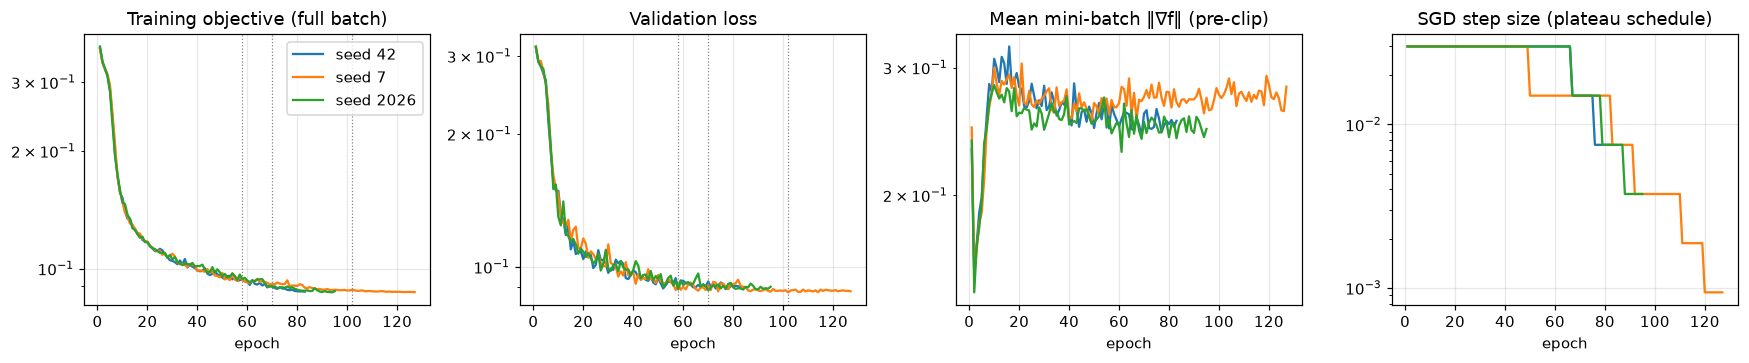

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for s, h in final_hists.items():
    axes[0].plot(h.epoch, h.train_obj, label=f"seed {s}")
    axes[1].plot(h.epoch, h.val_loss)
    axes[2].plot(h.epoch, h.grad_norm)
    axes[3].plot(h.epoch, h.lr)
    for ax in axes[:2]:
        ax.axvline(h.attrs["best_epoch"], color="grey", ls=":", lw=0.8)
axes[0].set(yscale="log", title="Training objective (full batch)", xlabel="epoch")
axes[1].set(yscale="log", title="Validation loss", xlabel="epoch")
axes[2].set(yscale="log", title="Mean mini-batch ‖∇f‖ (pre-clip)", xlabel="epoch")
axes[3].set(yscale="log", title="SGD step size (plateau schedule)", xlabel="epoch")
axes[0].legend(); plt.tight_layout(); plt.show()

## 8. Test-year breakdown (proposal §5)

In [13]:
rows_te = S["rows"][M["test"]]
act_te = L[rows_te]
nv_te = naive_forecasts(rows_te)
dates_te = days[rows_te]
season = pd.Series(dates_te.month).map({12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
                                        6: "Summer", 7: "Summer", 8: "Summer", 9: "Fall", 10: "Fall", 11: "Fall"}).to_numpy()
peak_cut = np.quantile(act_te.max(1), 0.9)
is_peak_day = act_te.max(1) >= peak_cut

models_te = {"LSTM": pred["test"], **nv_te}
rows_out = []
for grp_name, mask_fn in [("All days", lambda: np.ones(len(rows_te), bool)),
                          *[(f"Season: {s}", (lambda s=s: season == s)) for s in ["Winter", "Spring", "Summer", "Fall"]],
                          ("Peak days (top 10% daily peak)", lambda: is_peak_day)]:
    m = mask_fn()
    for name, p in models_te.items():
        rows_out.append({"subset": grp_name, "days": int(m.sum()), "model": name, **metrics(act_te[m], p[m])})
by_subset = pd.DataFrame(rows_out).pivot_table(index=["subset", "days"], columns="model", values="MAE")
print("Test MAE (MW) by subset")
by_subset[["LSTM", "Naive: previous day", "Naive: previous week"]]

Test MAE (MW) by subset


,model,LSTM,Naive: previous day,Naive: previous week
subset,days,,,
All days,307,"1,696.546","2,405.851","4,564.418"
Peak days (top 10% daily peak),31,"1,236.060","1,535.971","2,724.160"
Season: Fall,64,"1,704.203","2,143.792","4,716.713"
Season: Spring,92,"1,946.000","2,859.505","5,207.488"
Season: Summer,92,"1,525.665","1,996.948","3,516.786"
Season: Winter,59,"1,565.718","2,620.340","5,030.059"


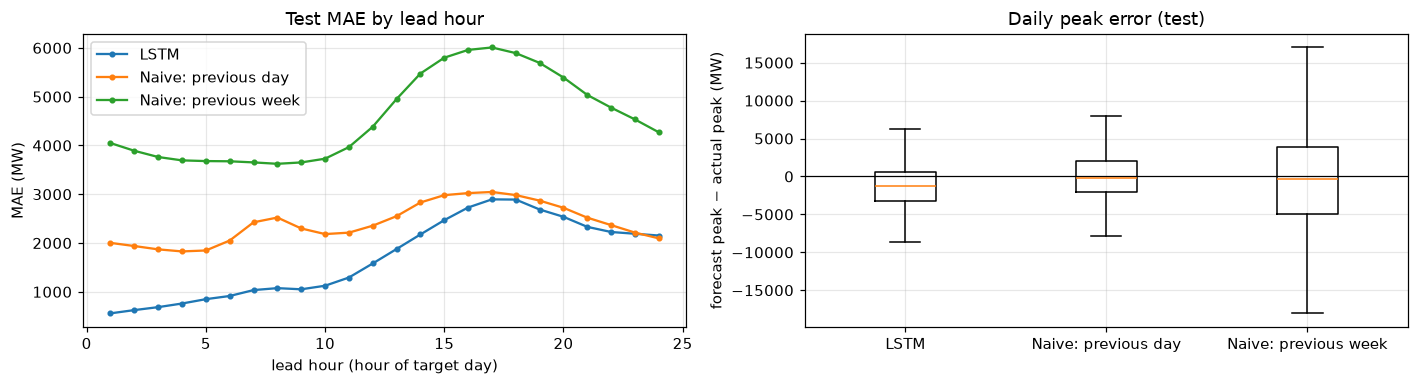

,daily-peak MAE (MW),mean peak bias (MW),peak hour within ±1 h (%)
LSTM,"2,824.208","-1,046.636",81.759
Naive: previous day,"3,034.217",15.088,78.176
Naive: previous week,"6,035.414",-103.767,70.033


In [14]:
# Error by lead hour (forecast issued at midnight, so lead hour = hour of day + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for name, p in models_te.items():
    axes[0].plot(np.arange(1, 25), np.abs(p - act_te).mean(0), marker="o", ms=3, label=name)
axes[0].set(xlabel="lead hour (hour of target day)", ylabel="MAE (MW)", title="Test MAE by lead hour")
axes[0].legend()

# Daily peak: what the dispatch QP cares about most
peak_err = {name: p.max(1) - act_te.max(1) for name, p in models_te.items()}
axes[1].boxplot(list(peak_err.values()), tick_labels=list(peak_err.keys()), showfliers=False)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(ylabel="forecast peak − actual peak (MW)", title="Daily peak error (test)")
plt.tight_layout(); plt.show()

peak_tab = pd.DataFrame({name: {"daily-peak MAE (MW)": np.abs(e).mean(),
                                "mean peak bias (MW)": e.mean(),
                                "peak hour within ±1 h (%)": 100 * (np.abs(models_te[name].argmax(1) - act_te.argmax(1)) <= 1).mean()}
                         for name, e in peak_err.items()}).T
peak_tab

In [15]:
# Paired day-level comparison: is the LSTM's improvement consistent across days?
day_mae = {name: np.abs(p - act_te).mean(1) for name, p in models_te.items()}
paired = []
for base in ["Naive: previous day", "Naive: previous week"]:
    d = day_mae["LSTM"] - day_mae[base]
    paired.append({"LSTM vs": base, "mean daily MAE diff (MW)": d.mean(),
                   "LSTM better on % of days": 100 * (d < 0).mean(),
                   "paired t p-value": stats.ttest_rel(day_mae["LSTM"], day_mae[base]).pvalue,
                   "Wilcoxon p-value": stats.wilcoxon(day_mae["LSTM"], day_mae[base]).pvalue})
pd.DataFrame(paired)

,LSTM vs,mean daily MAE diff (MW),LSTM better on % of days,paired t p-value,Wilcoxon p-value
0,Naive: previous day,-709.306,69.381,0.000,0.000
1,Naive: previous week,"-2,867.872",87.948,0.000,0.000


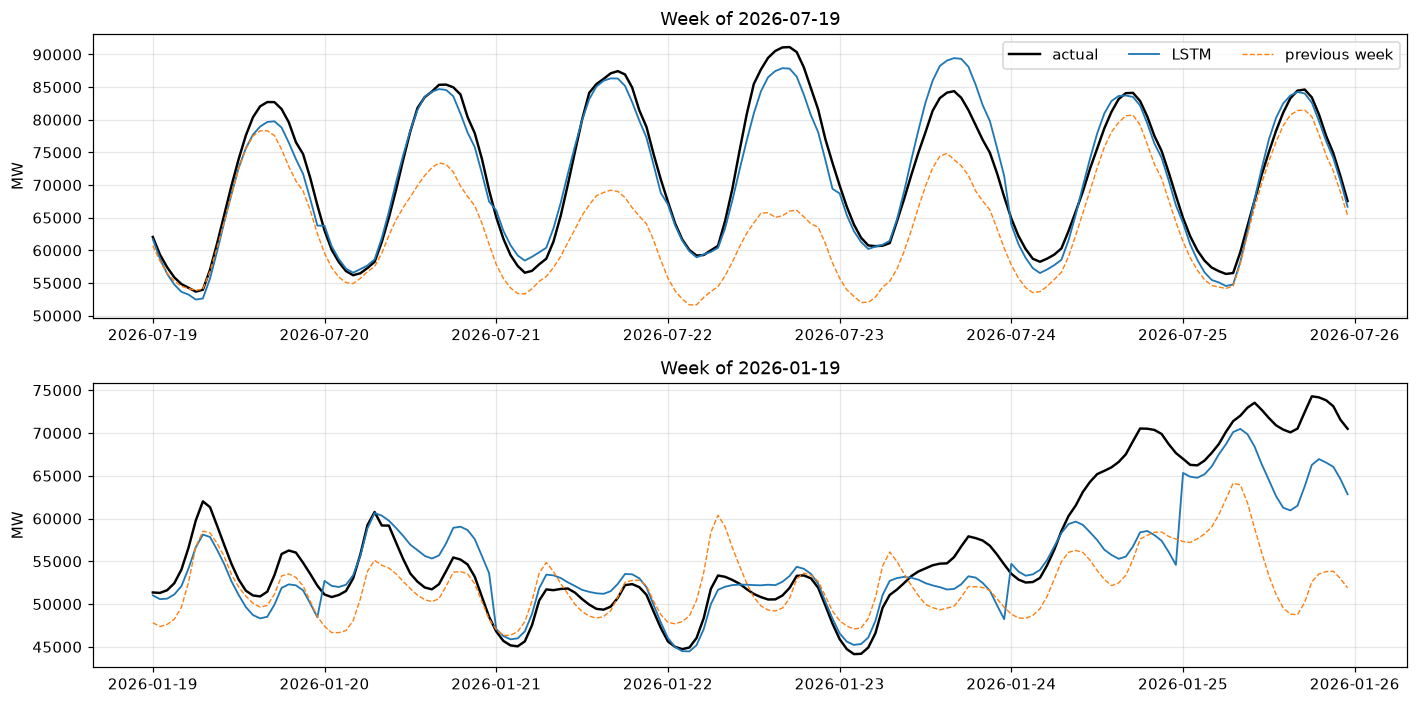

In [16]:
# Example weeks: a summer peak week and a winter week from the test year
def plot_week(start, ax):
    idx = np.where((dates_te >= pd.Timestamp(start)) & (dates_te < pd.Timestamp(start) + pd.Timedelta(days=7)))[0]
    t = pd.date_range(dates_te[idx[0]], periods=24 * len(idx), freq="h")
    ax.plot(t, act_te[idx].ravel(), "k", lw=1.6, label="actual")
    ax.plot(t, pred["test"][idx].ravel(), lw=1.2, label="LSTM")
    ax.plot(t, nv_te["Naive: previous week"][idx].ravel(), lw=0.9, ls="--", label="previous week")
    ax.set(title=f"Week of {pd.Timestamp(start).date()}", ylabel="MW")

top_day = dates_te[act_te.max(1).argmax()]
fig, axes = plt.subplots(2, 1, figsize=(13, 6.5))
plot_week(top_day - pd.Timedelta(days=3), axes[0])
plot_week("2026-01-19", axes[1])
axes[0].legend(ncol=3); plt.tight_layout(); plt.show()

## 9. Robustness checks
Both runs reuse `CONFIG` with seed 42, so they are compared against the main seed-42 model.

1. **Winter Storm Uri.** The main fit drops training samples whose input window or target day touches the Uri week, because load-shed demand during the storm is not normal demand. Here the model is refit *with* those samples to see whether it matters.
2. **Observed-weather upper bound.** The proposal excludes target-day weather because it is not known at 23:00 the day before. This run adds the **observed** target-day hourly temperature and dew point to the static inputs. It is **not an implementable forecast**: it shows how much a perfect weather forecast could add, i.e. a ceiling.

In [17]:
rob = []
def eval_row(label, model, data):
    out = {"run": label}
    for split in ["val", "test"]:
        rows = data["S"]["rows"][data["masks"][split]]
        m = metrics(L[rows], forecast_mw(model, data, split))
        out[f"{split} MAE"], out[f"{split} RMSE"] = m["MAE"], m["RMSE"]
    return out

rob.append(eval_row("Main (Uri excluded, no weather)", final_models[SEED], DATA))

d_uri = make_data(CONFIG, exclude_uri_train=False)
m_uri, _ = train_model(CONFIG, d_uri, seed=SEED)
rob.append(eval_row("Uri samples kept in training", m_uri, d_uri))

d_wx = make_data(CONFIG, use_weather=True)
m_wx, _ = train_model(CONFIG, d_wx, seed=SEED)
rob.append(eval_row("UPPER BOUND: + observed target-day weather", m_wx, d_wx))
pd.DataFrame(rob)

,run,val MAE,val RMSE,test MAE,test RMSE
0,"Main (Uri excluded, no weather)","1,645.631","2,493.098","1,735.163","2,542.682"
1,Uri samples kept in training,"1,645.890","2,527.314","1,743.109","2,578.231"
2,UPPER BOUND: + observed target-day weather,"1,061.968","1,453.922","1,224.795","1,638.025"


## 10. Supplementary: SGD variants on the same LSTM
The controlled optimizer study in the proposal (full-batch GD + backtracking vs mini-batch SGD) is run by a teammate on the feed-forward network. As a complement, this section trains the `CONFIG` LSTM with three first-order methods from the same seed and the same schedule, early stopping and clipping. It is judged on **validation only**. It is a fixed optimizer comparison, not tuning:
* plain mini-batch SGD (no momentum),
* SGD with Nesterov momentum (the method used above),
* Adam (adaptive per-parameter step sizes), shown only as a reference point.

,optimizer,val MAE,val RMSE,best epoch,epochs run,train s,final ‖∇f‖
0,"SGD (no momentum), lr 0.01","2,399.605","3,378.075",200,200,79.369,0.283
1,"SGD (no momentum), lr 0.05","1,780.387","2,635.267",144,169,46.938,0.324
2,"SGD + Nesterov, lr 0.03","1,645.631","2,493.098",58,83,24.984,0.259
3,"Adam, lr 0.001","1,713.288","2,545.563",24,49,16.261,0.240


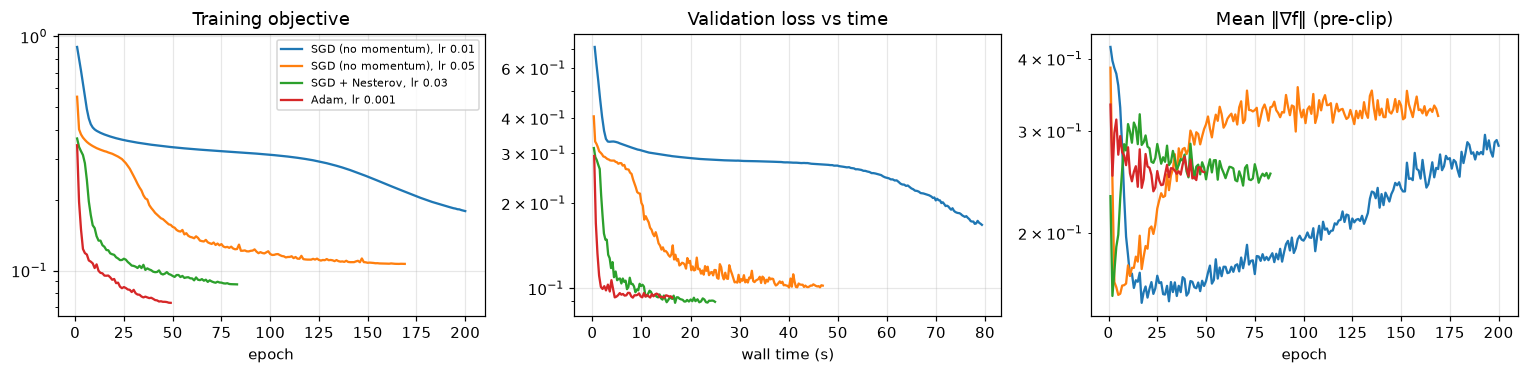

In [18]:
opt_runs = {
    "SGD (no momentum), lr 0.01": dict(CONFIG, optimizer="sgd", lr=0.01),
    "SGD (no momentum), lr 0.05": dict(CONFIG, optimizer="sgd", lr=0.05),
    f"SGD + Nesterov, lr {CONFIG['lr']}": dict(CONFIG, optimizer="sgd_nesterov"),
    "Adam, lr 0.001": dict(CONFIG, optimizer="adam", lr=0.001),
}
opt_hist, opt_rows = {}, []
for label, cfg in opt_runs.items():
    model, hist = train_model(cfg, DATA, seed=SEED)
    opt_hist[label] = hist
    rows = S["rows"][M["val"]]
    m = metrics(L[rows], forecast_mw(model, DATA, "val"))
    opt_rows.append({"optimizer": label, "val MAE": m["MAE"], "val RMSE": m["RMSE"],
                     "best epoch": hist.attrs["best_epoch"], "epochs run": len(hist),
                     "train s": hist.attrs["train_seconds"],
                     "final ‖∇f‖": hist.grad_norm.iloc[hist.attrs['best_epoch'] - 1]})
display(pd.DataFrame(opt_rows))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for label, h in opt_hist.items():
    axes[0].plot(h.epoch, h.train_obj, label=label)
    axes[1].plot(h.time, h.val_loss)
    axes[2].plot(h.epoch, h.grad_norm)
axes[0].set(yscale="log", xlabel="epoch", title="Training objective")
axes[1].set(yscale="log", xlabel="wall time (s)", title="Validation loss vs time")
axes[2].set(yscale="log", xlabel="epoch", title="Mean ‖∇f‖ (pre-clip)")
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 11. Export forecasts for the battery-dispatch QP and the comparison table
`lstm_day_ahead_forecasts.csv` has one row per (target day, hour) for the validation and test periods, in the same local-time 24-slot grid. The dispatch code can read `lstm_mw` as $\hat L_t$ for each day and use `actual_mw` for the perfect-forecast regret benchmark. The naive forecasts are included so the no-model reference uses identical days and hours.

In [19]:
frames = []
for split in ["val", "test"]:
    rows = S["rows"][M[split]]
    nv = naive_forecasts(rows)
    n = len(rows)
    frames.append(pd.DataFrame({
        "date": np.repeat(days[rows].date, 24),
        "hour": np.tile(np.arange(24), n),
        "timestamp": (np.repeat(days[rows].values, 24) + np.tile(np.arange(24), n) * np.timedelta64(1, "h")),
        "split": split,
        "actual_mw": L[rows].ravel(),
        "lstm_mw": pred[split].ravel(),
        "naive_prev_day_mw": nv["Naive: previous day"].ravel(),
        "naive_prev_week_mw": nv["Naive: previous week"].ravel(),
    }))
fc = pd.concat(frames, ignore_index=True)
fc.to_csv(OUT_DIR / "lstm_day_ahead_forecasts.csv", index=False)

summary.to_csv(OUT_DIR / "lstm_metrics_summary.csv", index=False)
for s, m in final_models.items():
    torch.save(m.state_dict(), OUT_DIR / f"lstm_seed{s}.pt")
json.dump({"config": CONFIG, "seeds": FINAL_SEEDS,
           "params": n_params(final_models[SEED]), "infer_ms_per_forecast": infer_ms_per_day},
          open(OUT_DIR / "lstm_config.json", "w"), indent=2, default=str)
print(fc.shape); print(sorted(p.name for p in OUT_DIR.iterdir()))
fc.head()

(24912, 8)
['lstm_config.json', 'lstm_day_ahead_forecasts.csv', 'lstm_metrics_summary.csv', 'lstm_seed2026.pt', 'lstm_seed42.pt', 'lstm_seed7.pt']


,date,hour,timestamp,split,actual_mw,lstm_mw,naive_prev_day_mw,naive_prev_week_mw
0,2024-01-01,0,2024-01-01 00:00:00,val,"41,223.480","40,410.053","43,755.319","40,028.793"
1,2024-01-01,1,2024-01-01 01:00:00,val,"41,479.400","39,475.373","43,263.260","39,519.356"
2,2024-01-01,2,2024-01-01 02:00:00,val,"41,472.770","38,956.337","43,022.977","39,245.845"
3,2024-01-01,3,2024-01-01 03:00:00,val,"41,477.441","38,890.875","43,245.821","39,300.755"
4,2024-01-01,4,2024-01-01 04:00:00,val,"42,184.193","39,453.198","43,654.080","39,899.401"


## 12. Hyperparameter tuning hooks (for the tuning teammate)
Everything above uses the single fixed `CONFIG`. This section gives a teammate what they need to tune it **without touching the test year**.

* `run_trial(overrides, seed)` copies `CONFIG`, applies the changed keys, trains one model and returns **validation** metrics (MAE, RMSE, MAPE), the best epoch and the training time. It never computes test-set numbers.
* Data tensors are cached per input design (`mode`, `lookback`, `level_days`), so trials that only change network or optimizer settings skip rebuilding the data.
* Every trial is appended to `lstm_outputs/tuning_log.csv`, so results survive a kernel restart and can be shared.

**Workflow**
1. Set `RUN_TUNING = True` below and edit `search_space`, or call `run_trial({...})` directly.
2. Pick the setting with the lowest validation MAE. Re-running the top 2–3 with `seed=7` and `seed=2026` is a good way to check that the win is not seed noise.
3. Copy the winning values into `CONFIG` in §0 and **Restart & Run All**. Sections 7–11 then report the test year once for the tuned model.

Typical ranges to explore: `lookback` 7–28, `hidden` 32–128, `layers` 1–3, `dropout` 0–0.4, `lr` 0.003–0.05, `batch` 16–128, `wd` 0–1e-4. One trial takes about 30–120 s on a laptop CPU.

In [20]:
import itertools, random

_data_cache = {}
TUNING_LOG = OUT_DIR / "tuning_log.csv"

def get_data(cfg):
    key = (cfg["mode"], cfg["lookback"], cfg["level_days"])
    if key not in _data_cache:
        _data_cache[key] = make_data(cfg)
    return _data_cache[key]

def run_trial(overrides=None, seed=SEED, log=True):
    # Train CONFIG + overrides once; return VALIDATION metrics only.
    unknown = set(overrides or {}) - set(CONFIG)
    if unknown:
        raise KeyError(f"Unknown hyperparameter(s): {unknown}. Valid keys: {list(CONFIG)}")
    cfg = {**CONFIG, **(overrides or {})}
    data = get_data(cfg)
    model, hist = train_model(cfg, data, seed=seed)
    rows = data["S"]["rows"][data["masks"]["val"]]
    m = metrics(L[rows], forecast_mw(model, data, "val"))
    out = {**cfg, "seed": seed, "val_MAE": m["MAE"], "val_RMSE": m["RMSE"], "val_MAPE%": m["MAPE%"],
           "best_epoch": hist.attrs["best_epoch"], "epochs_run": len(hist),
           "train_s": round(hist.attrs["train_seconds"], 1), "params": n_params(model)}
    if log:
        pd.DataFrame([out]).to_csv(TUNING_LOG, mode="a", header=not TUNING_LOG.exists(), index=False)
    return out

def grid_search(space, seed=SEED):
    # space: dict of key -> list of values. Every combination is tried.
    keys = list(space)
    return pd.DataFrame([run_trial(dict(zip(keys, vals)), seed)
                         for vals in itertools.product(*space.values())]).sort_values("val_MAE")

def random_search(space, n_trials=10, seed=SEED):
    # Sample n_trials random combinations from space (cheaper than a full grid).
    rng = random.Random(seed)
    trials = [{k: rng.choice(v) for k, v in space.items()} for _ in range(n_trials)]
    return pd.DataFrame([run_trial(t, seed) for t in trials]).sort_values("val_MAE")

In [21]:
RUN_TUNING = False   # set True to run the example search (takes several minutes)

search_space = {
    "lookback": [7, 14, 28],
    "hidden":   [32, 64, 128],
    "lr":       [0.01, 0.03],
}

if RUN_TUNING:
    results = grid_search(search_space)          # or: random_search(search_space, n_trials=8)
    display(results[["lookback", "hidden", "lr", "val_MAE", "val_RMSE", "best_epoch", "train_s"]])
else:
    print("Tuning skipped. Example single trial call:\n"
          "  run_trial({'hidden': 128, 'lr': 0.01})")

Tuning skipped. Example single trial call:
  run_trial({'hidden': 128, 'lr': 0.01})


## 13. Results summary for the report

In [22]:
te = summary[summary.split == "test"].set_index("model")
va = summary[summary.split == "val"].set_index("model")
print("Configuration:", {k: CONFIG[k] for k in ["mode", "lookback", "hidden", "layers", "optimizer", "lr", "batch"]})
print(f"Validation MAE: LSTM {va.loc['LSTM (3-seed mean)','MAE']:,.0f} MW vs previous-week {va.loc['Naive: previous week','MAE']:,.0f} MW")
print(f"Test MAE:       LSTM {te.loc['LSTM (3-seed mean)','MAE']:,.0f} MW  "
      f"(MAPE {te.loc['LSTM (3-seed mean)','MAPE%']:.2f}%), RMSE {te.loc['LSTM (3-seed mean)','RMSE']:,.0f} MW")
print(f"                previous-day {te.loc['Naive: previous day','MAE']:,.0f} MW, previous-week {te.loc['Naive: previous week','MAE']:,.0f} MW")
print(f"Seed spread (test MAE std): {seed_tab[seed_tab.split=='test'].MAE.std():,.0f} MW")

Configuration: {'mode': 'day', 'lookback': 14, 'hidden': 64, 'layers': 2, 'optimizer': 'sgd_nesterov', 'lr': 0.03, 'batch': 32}
Validation MAE: LSTM 1,622 MW vs previous-week 4,615 MW
Test MAE:       LSTM 1,697 MW  (MAPE 2.81%), RMSE 2,502 MW
                previous-day 2,406 MW, previous-week 4,564 MW
Seed spread (test MAE std): 17 MW


**Findings from our run** (exact numbers shift slightly between machines and PyTorch versions; re-check against the outputs above before quoting):

* **Setting used.** One fixed configuration: day-step LSTM, 14-day lookback, 2 layers × 64 hidden units, SGD with Nesterov momentum at step size 0.03, batches of 32 days. Tuning is left to a teammate via §12.
* **Test year (2026, evaluated once).** The 3-seed LSTM reached **MAE ≈ 1,700 MW (MAPE ≈ 2.8%)**, against ≈ 2,400 MW for the previous-day naive and ≈ 4,560 MW for previous-week. It beat previous-day on about 70% of test days and previous-week on about 88% (paired t and Wilcoxon p < 0.001). Seed-to-seed spread was small (std ≈ 16 MW), so the result does not depend on a lucky initialisation.
* **Where it struggles.** Spring had the largest error. Error rises with lead hour into the afternoon peak. The LSTM **under-forecasts the daily peak by about 1 GW on average**, although it places the peak hour within ±1 h on ~82% of days. *This matters for the battery QP:* a low peak forecast makes the scheduled peak-shaving look easier than it will be, so it should show up in the regret analysis.
* **Optimisation.** Plain SGD at lr 0.01 had not converged after 200 epochs (val MAE ≈ 2,400 MW). Raising the step to 0.05 helped, and adding Nesterov momentum reached the best validation loss in fewer epochs and less time. Adam converged fastest in wall time but to a slightly worse validation error.
* **Robustness.** Keeping the Uri week in training barely changed results. Adding *observed* target-day weather cut test MAE to ≈ 1,280 MW. That is an **upper bound**, not a usable forecast, but it shows that a weather-forecast input is the most promising next step.